# Generalidades del proyecto

Este notebook recopila la practica relacionada al aprendizaje supervisado tarea de clasificacion con datos realistas de kaggle sobre los resultados de la prueba Saber 11 del ICFES (Colombia), para predecir con base en las caracteristicas del colegio, del hogar y del estudiante, si este alcanza o no un puntaje global de 300 o mas puntos (alto desempeno escolar, criterio que se justifica por el uso practico que se da a los puntajes en Colombia para becas y programas de alta demanda).

Enlace de los datos: https://www.kaggle.com/datasets/andyrubiano/saber-11-muestra-2022-4

Fuente original de los datos: ICFES, Resultados unicos Saber 11 del periodo 2022-4 (https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe)

Esto se resolvera basado en la unidad de conexion en los tema de machine learning y estrategias de clasificacion como maquinas de soporte vectorial, y arboles de decision

# Importar herramientas necesarias

In [ ]:
import pandas as pd # manejo de datos
import matplotlib.pyplot as plt # graficos
import seaborn as sns # graficos
from sklearn.model_selection import train_test_split # division de datos en entrenamiento y prueba
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler # preprocesamiento de datos
# importar modelos de clasificacion
from sklearn.linear_model import LogisticRegression # regresion logistica
from sklearn.svm import SVC # maquinas de soporte vectorial
from sklearn.tree import DecisionTreeClassifier # arboles de decision
from sklearn.ensemble import RandomForestClassifier # random forest
# importar metricas
from sklearn.metrics import accuracy_score # Metrica para clasificacion
import joblib
import json

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Cargar los datos del problema

En este caso se carga saber11_muestra_1000.csv una muestra de 1.000 estudiantes de la prueba Saber 11 del periodo 2022-4 (calendario A) del ICFES. Los puntajes van de 0 a 100 por area y de 0 a 500 en punt_global.

In [ ]:
ruta_datos = "/content/drive/MyDrive/IA-Explorador-Virtual-2026/datos/saber11_muestra_1000.csv"

df_saber11 = pd.read_csv(ruta_datos)

df_saber11.head(3)

,periodo,estu_tipodocumento,estu_consecutivo,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,...,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,desemp_ingles,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global
0,20224,CC,SB11202240001009,URBANO,N,A,TÉCNICO/ACADÉMICO,105040000212,105040000212,5,...,NaN,NaN,NaN,A1,52.0,24,40,39,36,180
1,20224,CC,SB11202240001762,RURAL,N,A,ACADÉMICO,273616000892,273616000892,73,...,Si,Si,Si,A-,42.0,40,43,32,42,197
2,20224,TI,SB11202240002799,URBANO,N,A,TÉCNICO/ACADÉMICO,111001024732,111001024732,11,...,Si,Si,Si,B1,78.0,60,58,62,64,312


# Definir la variable objetivo del problema

El dataset de Saber 11 no trae una columna de estado como la loan_status del caso crediticio: la descripcion del dataset en Kaggle indica que se puede trabajar una clasificacion con un nivel de desempeno derivado del puntaje global.

En esta practica se define como variable objetivo una clase binaria llamada nivel_desempeno a partir de un umbral de puntaje:

1. nivel_desempeno = 1 (alto desempeno): si punt_global >= UMBRAL. El umbral de inicio lo planteo el autor de la practica tomando como referencia el puntaje de 370 asociado a programas de medicina en Colombia, pero con la muestra de 1.000 registros solo 5 estudiantes alcanzan ese puntaje (0.5%), lo que hace que los modelos aprendan a predecir casi siempre la clase 0 y la prueba sea degenerada, por esta razon se trabajo con UMBRAL = 300 con el cual la clase 1 queda en el 18.4% de la muestra (184 registros) y el desbalance queda cercano al del caso crediticio original.
2. nivel_desempeno = 0: si punt_global < UMBRAL.

UMBRAL queda como una constante en la siguiente celda de modo que se puede cambiar y reejecutar todo el notebook si se quiere probar otro criterio.

Importante: como la clase se deriva del puntaje global, y por recomendacion de la propia descripcion del dataset, los puntajes por area (punt_ingles, punt_matematicas, punt_sociales_ciudadanas, punt_c_naturales, punt_lectura_critica), desemp_ingles y punt_global no deben usarse como variables explicativas porque describen directamente la variable objetivo (fuga de datos), al final se omiten al seleccionar las columnas del problema.

In [ ]:
# definir el umbral de puntaje global que define la clase 1
UMBRAL = 300

# crear la variable objetivo binaria: 1 si punt_global >= UMBRAL, 0 en caso contrario
df_saber11["nivel_desempeno"] = (df_saber11["punt_global"] >= UMBRAL).astype(int)

# revisar la creacion de la variable
df_saber11[["punt_global", "nivel_desempeno"]].head(3)

,punt_global,nivel_desempeno
0,180,0
1,197,0
2,312,1


# Analisis de los datos

Etapa en donde se analizan los datos con el fin de identificar correctamente mi variable objetivo, determinar si todas las columnas son necesarias, verificar si existen datos nulos o faltantes, el comportamiento de los datos. En resumen son los siguientes pasos:

1. Revisar si existen datos nulos o faltantes
2. Implementar estrategias de imputacion o relleno de datos si es necesario
3. Revisar si existen datos duplicados
4. Identificar posible datos atipicos o extraños que no describan correctamente mi problema
5. Analizar el comportamiento de mi variable objetivo, para determinar que tipo de problema tengo entre si es un conjunto de datos balanceado o desbalanceado
6. Aplicar estrategias de balanceo de datos si es necesario

## 1. Revisar datos nulos

In [ ]:
df_saber11.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 52 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   periodo                        1000 non-null   int64  
 1   estu_tipodocumento             1000 non-null   object 
 2   estu_consecutivo               1000 non-null   object 
 3   cole_area_ubicacion            1000 non-null   object 
 4   cole_bilingue                  827 non-null    object 
 5   cole_calendario                1000 non-null   object 
 6   cole_caracter                  962 non-null    object 
 7   cole_cod_dane_establecimiento  1000 non-null   int64  
 8   cole_cod_dane_sede             1000 non-null   int64  
 9   cole_cod_depto_ubicacion       1000 non-null   int64  
 10  cole_cod_mcpio_ubicacion       1000 non-null   int64  
 11  cole_codigo_icfes              1000 non-null   int64  
 12  cole_depto_ubicacion           1000 non-null   ob

In [ ]:
df_saber11.isnull().sum()

,0
periodo,0
estu_tipodocumento,0
estu_consecutivo,0
cole_area_ubicacion,0
cole_bilingue,173
cole_calendario,0
cole_caracter,38
cole_cod_dane_establecimiento,0
cole_cod_dane_sede,0
cole_cod_depto_ubicacion,0


In [ ]:
# Analizar el comportamiento de las filas que reportan datos nulos
df_nulos = df_saber11[df_saber11.isnull().any(axis=1)]

df_nulos.info()

<class 'pandas.core.frame.DataFrame'>
Index: 269 entries, 0 to 999
Data columns (total 52 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   periodo                        269 non-null    int64  
 1   estu_tipodocumento             269 non-null    object 
 2   estu_consecutivo               269 non-null    object 
 3   cole_area_ubicacion            269 non-null    object 
 4   cole_bilingue                  96 non-null     object 
 5   cole_calendario                269 non-null    object 
 6   cole_caracter                  231 non-null    object 
 7   cole_cod_dane_establecimiento  269 non-null    int64  
 8   cole_cod_dane_sede             269 non-null    int64  
 9   cole_cod_depto_ubicacion       269 non-null    int64  
 10  cole_cod_mcpio_ubicacion       269 non-null    int64  
 11  cole_codigo_icfes              269 non-null    int64  
 12  cole_depto_ubicacion           269 non-null    object 


In [ ]:
df_nulos["nivel_desempeno"].value_counts()

,count
nivel_desempeno,
0,231
1,38


In [ ]:
df_nulos.describe()

,periodo,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,cole_cod_mcpio_ubicacion,cole_codigo_icfes,estu_cod_depto_presentacion,estu_cod_mcpio_presentacion,estu_cod_reside_depto,estu_cod_reside_mcpio,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global,nivel_desempeno
count,269.0,2.690000e+02,2.690000e+02,269.000000,269.000000,269.000000,269.000000,269.000000,269.000000,269.000000,265.000000,269.000000,269.000000,269.000000,269.000000,269.000000,269.000000
mean,20224.0,2.337790e+11,2.341571e+11,34.750929,35025.921933,385640.408922,34.828996,35074.828996,34.691450,34957.810409,47.958491,48.159851,45.423792,46.925651,50.992565,239.353160,0.141264
std,0.0,9.512041e+10,9.576721e+10,27.044899,27044.275388,284406.937044,26.995863,26998.960303,27.093356,27091.945362,13.329243,12.235885,11.486801,10.070000,10.781754,50.996175,0.348943
min,20224.0,1.050010e+11,1.050010e+11,5.000000,5001.000000,406.000000,5.000000,5001.000000,5.000000,5001.000000,0.000000,21.000000,19.000000,0.000000,28.000000,117.000000,0.000000
25%,20224.0,1.444300e+11,1.440010e+11,11.000000,11001.000000,134833.000000,11.000000,11001.000000,11.000000,11001.000000,38.000000,38.000000,37.000000,40.000000,43.000000,203.000000,0.000000
50%,20224.0,2.236700e+11,2.236780e+11,23.000000,23855.000000,233940.000000,25.000000,25126.000000,25.000000,25099.000000,46.000000,49.000000,44.000000,45.000000,52.000000,232.000000,0.000000
75%,20224.0,3.117640e+11,3.170010e+11,54.000000,54810.000000,717025.000000,54.000000,54001.000000,54.000000,54810.000000,55.000000,58.000000,53.000000,54.000000,58.000000,275.000000,0.000000
max,20224.0,4.253771e+11,4.253771e+11,95.000000,95001.000000,806620.000000,95.000000,95001.000000,95.000000,95001.000000,100.000000,78.000000,76.000000,75.000000,80.000000,368.000000,1.000000


Tomando en cuenta el comportamiento estadistico de las columnas que cuentan con datos nulos, se opta por imputar datos con la moda, es decir el valor que mas se repite, en las columnas de texto del colegio y del hogar (cole_bilingue, cole_caracter y las 9 columnas fami_* del cuestionario del hogar). A diferencia del caso crediticio ninguna de estas columnas es numerica, por lo cual no aplica imputar con promedio; la descripcion del dataset indica que los faltantes estan concentrados en esas columnas.

Las 4 filas sin datos en punt_ingles y desemp_ingles no se imputan, porque esas columnas de resultados se omitiran por fuga de datos al seleccionar las columnas del problema.

## 2. Aplicar estrategia de imputacion de datos

In [ ]:
# imputar con la moda de los datos las columnas de texto del colegio y del cuestionario del hogar
columnas_imputar = [
    "cole_bilingue", "cole_caracter",
    "fami_cuartoshogar", "fami_educacionmadre", "fami_educacionpadre", "fami_estratovivienda",
    "fami_personashogar", "fami_tieneautomovil", "fami_tienecomputador", "fami_tieneinternet",
    "fami_tienelavadora",
]

for columna in columnas_imputar:
    df_saber11[columna] = df_saber11[columna].fillna(df_saber11[columna].mode()[0])

# Revisar si ya no tenemos datos nulos (solo quedan los de punt_ingles y desemp_ingles que se omitiran)
df_saber11.isnull().sum()

,0
periodo,0
estu_tipodocumento,0
estu_consecutivo,0
cole_area_ubicacion,0
cole_bilingue,0
cole_calendario,0
cole_caracter,0
cole_cod_dane_establecimiento,0
cole_cod_dane_sede,0
cole_cod_depto_ubicacion,0


In [ ]:
df_saber11.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 52 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   periodo                        1000 non-null   int64  
 1   estu_tipodocumento             1000 non-null   object 
 2   estu_consecutivo               1000 non-null   object 
 3   cole_area_ubicacion            1000 non-null   object 
 4   cole_bilingue                  1000 non-null   object 
 5   cole_calendario                1000 non-null   object 
 6   cole_caracter                  1000 non-null   object 
 7   cole_cod_dane_establecimiento  1000 non-null   int64  
 8   cole_cod_dane_sede             1000 non-null   int64  
 9   cole_cod_depto_ubicacion       1000 non-null   int64  
 10  cole_cod_mcpio_ubicacion       1000 non-null   int64  
 11  cole_codigo_icfes              1000 non-null   int64  
 12  cole_depto_ubicacion           1000 non-null   ob

## 3. Revisar datos duplicados

In [ ]:
df_saber11.duplicated().sum()

np.int64(0)

In [ ]:
# Eliminar datos duplicados si existen
df_saber11 = df_saber11.drop_duplicates()
# Verificar que mis datos ya no tengan datos duplicados
df_saber11.duplicated().sum()

np.int64(0)

In [ ]:
df_saber11.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 52 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   periodo                        1000 non-null   int64  
 1   estu_tipodocumento             1000 non-null   object 
 2   estu_consecutivo               1000 non-null   object 
 3   cole_area_ubicacion            1000 non-null   object 
 4   cole_bilingue                  1000 non-null   object 
 5   cole_calendario                1000 non-null   object 
 6   cole_caracter                  1000 non-null   object 
 7   cole_cod_dane_establecimiento  1000 non-null   int64  
 8   cole_cod_dane_sede             1000 non-null   int64  
 9   cole_cod_depto_ubicacion       1000 non-null   int64  
 10  cole_cod_mcpio_ubicacion       1000 non-null   int64  
 11  cole_codigo_icfes              1000 non-null   int64  
 12  cole_depto_ubicacion           1000 non-null   ob

## 4. Revisar comportamiento de datos

Esto enfocado a identificar posibles datos atipicos o extraños en los datos.

Para graficar la edad, y a diferencia del caso crediticio que traia la columna person_age, en este dataset la edad no viene en una columna numerica, por lo cual se deriva a partir de la fechanacimiento: como el periodo 2022-4 corresponde a la segunda mitad de 2022, se toma como referencia la fecha tentativa del examen 2022-08-01.

In [ ]:
# derivar la edad del estudiante a partir de la fechanacimiento
fechanacimiento = pd.to_datetime(df_saber11["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")
df_saber11["estu_edad"] = ((pd.Timestamp("2022-08-01") - fechanacimiento).dt.days // 365).astype(int)

# revisar el comportamiento de las columnas numericas del conjunto de datos
df_saber11.describe()

,periodo,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,cole_cod_mcpio_ubicacion,cole_codigo_icfes,estu_cod_depto_presentacion,estu_cod_mcpio_presentacion,estu_cod_reside_depto,estu_cod_reside_mcpio,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global,nivel_desempeno,estu_edad
count,1000.0,1.000000e+03,1.000000e+03,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,996.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20224.0,2.026417e+11,2.036083e+11,33.478000,33741.121000,316539.795000,33.679000,33929.131000,33.493000,33754.700000,49.571285,50.278000,47.384000,48.807000,52.952000,249.155000,0.184000,17.322000
std,0.0,9.144664e+10,9.157255e+10,26.680018,26690.853257,298753.031911,26.774182,26785.218421,26.685653,26693.569584,13.051577,11.909431,11.713144,10.061261,10.477857,50.505126,0.387678,3.634767
min,20224.0,1.050010e+11,1.050010e+11,5.000000,5001.000000,190.000000,5.000000,5001.000000,5.000000,5001.000000,0.000000,21.000000,19.000000,0.000000,28.000000,117.000000,0.000000,15.000000
25%,20224.0,1.158138e+11,1.158808e+11,11.000000,11001.000000,64106.500000,11.000000,11001.000000,11.000000,11001.000000,39.000000,41.000000,38.000000,41.000000,45.000000,211.000000,0.000000,16.000000
50%,20224.0,1.730010e+11,1.734270e+11,23.000000,23500.000000,158106.000000,23.000000,23417.000000,23.000000,23527.500000,48.000000,50.000000,47.000000,47.500000,53.000000,245.000000,0.000000,17.000000
75%,20224.0,3.050010e+11,3.050010e+11,54.000000,54503.000000,709291.500000,54.000000,54591.000000,54.000000,54503.000000,58.000000,59.000000,56.000000,56.000000,61.000000,288.000000,0.000000,18.000000
max,20224.0,4.708230e+11,4.708230e+11,97.000000,97001.000000,806620.000000,97.000000,97001.000000,97.000000,97001.000000,100.000000,100.000000,82.000000,77.000000,100.000000,412.000000,1.000000,72.000000


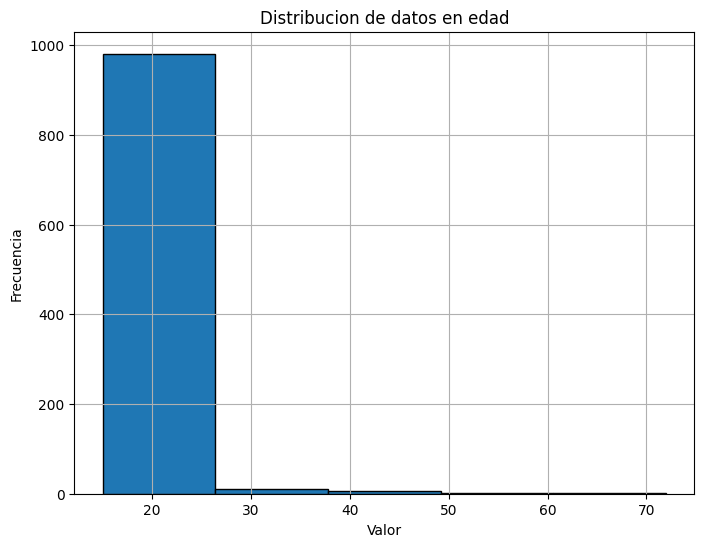

In [ ]:
# graficar columna estu_edad para verificar el comportamiento de los datos ya que se nota un valor maximo de 72 años

plt.figure(figsize=(8,6))
plt.hist(df_saber11['estu_edad'], bins=5, edgecolor='black')
plt.title('Distribucion de datos en edad')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.grid(True)
plt.show()

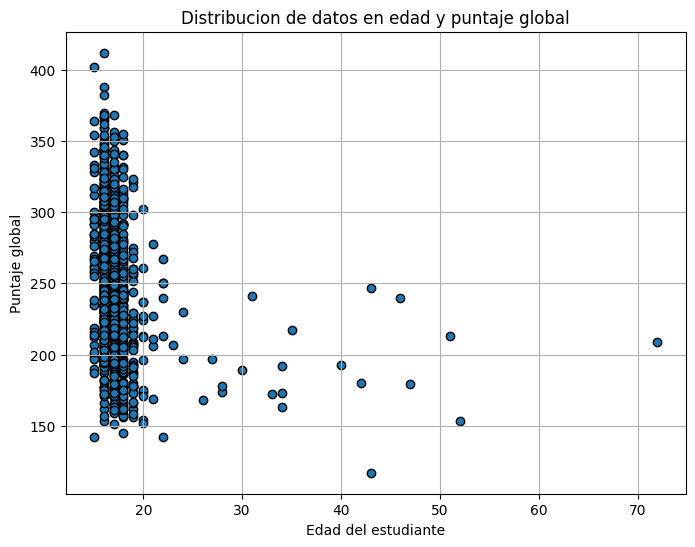

In [ ]:
# graficar nube de puntos

plt.figure(figsize=(8,6))
plt.scatter(x=df_saber11['estu_edad'], y=df_saber11['punt_global'], edgecolor='black')
plt.title('Distribucion de datos en edad y puntaje global')
plt.xlabel('Edad del estudiante')
plt.ylabel('Puntaje global')
plt.grid(True)
plt.show()

Al revisar los datos se nota que la mayor edad es de 72 años, y al graficar se confirma que no son datos imposibles ni atipicos: la descripcion del dataset aclara que la edad tiene una cola de adultos pertenecientes a jornadas nocturnas y sabatinas, hasta de 72 años, es decir son estudiantes reales de la educacion para adultos.

Por otro lado los puntajes por area se mueven entre 0 y 100 y punt_global entre 117 y 412, dentro del rango valido de 0 a 500 que describe el documento del dataset, por lo que no hay datos extraños en los resultados como si ocurria en el caso crediticio.

## Omitir datos atipicos identificados

Solo tomaremos los datos basados en un criterio de plausibilidad de la educacion media, es decir que un estudiante de Saber 11 tenga al menos 14 años, verificando que edad no sea menor a ese valor.

A diferencia del caso crediticio aqui no se identificaron datos que violen reglas de negocio o que sean imposibles (no hay edades de mas de 100 años ni puntajes fuera del rango del examen), por lo cual el filtro no elimina ningun registro de esta muestra.

In [ ]:
# selecionar datos con valores de 14 años o mas en la columna estu_edad para asegurar
# la plausibilidad de que el registro corresponde a un estudiante de educacion media
df_saber11 = df_saber11[df_saber11['estu_edad'] >= 14]

# revisar el tamano del conjunto de datos despues del filtro
df_saber11.shape

(1000, 53)

In [ ]:
df_saber11.describe()

,periodo,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,cole_cod_mcpio_ubicacion,cole_codigo_icfes,estu_cod_depto_presentacion,estu_cod_mcpio_presentacion,estu_cod_reside_depto,estu_cod_reside_mcpio,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global,nivel_desempeno,estu_edad
count,1000.0,1.000000e+03,1.000000e+03,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,996.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20224.0,2.026417e+11,2.036083e+11,33.478000,33741.121000,316539.795000,33.679000,33929.131000,33.493000,33754.700000,49.571285,50.278000,47.384000,48.807000,52.952000,249.155000,0.184000,17.322000
std,0.0,9.144664e+10,9.157255e+10,26.680018,26690.853257,298753.031911,26.774182,26785.218421,26.685653,26693.569584,13.051577,11.909431,11.713144,10.061261,10.477857,50.505126,0.387678,3.634767
min,20224.0,1.050010e+11,1.050010e+11,5.000000,5001.000000,190.000000,5.000000,5001.000000,5.000000,5001.000000,0.000000,21.000000,19.000000,0.000000,28.000000,117.000000,0.000000,15.000000
25%,20224.0,1.158138e+11,1.158808e+11,11.000000,11001.000000,64106.500000,11.000000,11001.000000,11.000000,11001.000000,39.000000,41.000000,38.000000,41.000000,45.000000,211.000000,0.000000,16.000000
50%,20224.0,1.730010e+11,1.734270e+11,23.000000,23500.000000,158106.000000,23.000000,23417.000000,23.000000,23527.500000,48.000000,50.000000,47.000000,47.500000,53.000000,245.000000,0.000000,17.000000
75%,20224.0,3.050010e+11,3.050010e+11,54.000000,54503.000000,709291.500000,54.000000,54591.000000,54.000000,54503.000000,58.000000,59.000000,56.000000,56.000000,61.000000,288.000000,0.000000,18.000000
max,20224.0,4.708230e+11,4.708230e+11,97.000000,97001.000000,806620.000000,97.000000,97001.000000,97.000000,97001.000000,100.000000,100.000000,82.000000,77.000000,100.000000,412.000000,1.000000,72.000000


En el caso crediticio se omitian los registros con tiempo de empleado en cero porque una entidad financiera no presta dinero a una persona sin historial laboral (regla de negocio del problema). En este dataset no existe una regla de negocio equivalente que implique eliminar registros, y el caso de las 4 filas sin punt_ingles y desemp_ingles se resuelve al omitir dichas columnas por fuga de datos, por lo que se conservan las 1.000 filas.

In [ ]:
df_saber11.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 53 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   periodo                        1000 non-null   int64  
 1   estu_tipodocumento             1000 non-null   object 
 2   estu_consecutivo               1000 non-null   object 
 3   cole_area_ubicacion            1000 non-null   object 
 4   cole_bilingue                  1000 non-null   object 
 5   cole_calendario                1000 non-null   object 
 6   cole_caracter                  1000 non-null   object 
 7   cole_cod_dane_establecimiento  1000 non-null   int64  
 8   cole_cod_dane_sede             1000 non-null   int64  
 9   cole_cod_depto_ubicacion       1000 non-null   int64  
 10  cole_cod_mcpio_ubicacion       1000 non-null   int64  
 11  cole_codigo_icfes              1000 non-null   int64  
 12  cole_depto_ubicacion           1000 non-null   ob

## 5. Analizar el comportamiento de la variable objetivo

En este caso la variable objetivo es la columna nivel_desempeno que se creo al inicio del notebook, ya que el conjunto no trae una columna de estado como loan_status en el caso crediticio; esta columna registra si el estudiante alcanzo (1) o no (0) un puntaje global de por lo menos UMBRAL (300) puntos, criterio que se justifica por el uso practico de los puntajes Saber 11 en Colombia (becas y programas de alta demanda).

Se analiza la distribucion de cantidad de registros por categoria o clase, en este caso cuantos registros son 1 y cuantos son 0

In [ ]:
df_saber11["nivel_desempeno"].value_counts()

,count
nivel_desempeno,
0,816
1,184


Al revisar el comportamiento de la variable objetivo se nota que tenemos 816 registros con valor de 0 y 184 con valor de 1 esto indica que estamos trabajando en un conjunto de datos desbalanceado (cerca de 4.4 estudiantes que no alcanzan el umbral por cada uno que lo alcanza).

El desbalance es similar al del caso crediticio original (mas de 21 mil registros con valor de 0 frente a mas de 5 mil con valor de 1, cerca de 4 a 1). El balanceo de datos no es obligatorio en este punto por lo cual se trabajara con esta particularidad ya que se van a entrenar 4 estrategias diferentes y se quiere verificar que modelo trabaja mejor con este tipo de datos, mediante el calculo de la metrica accuracy.

## 6. Balanceo de datos

Como se indico en el analisis de la variable objetivo, el conjunto queda desbalanceado (81.6% clase 0 frente a 18.4% clase 1), por lo cual no se aplica ninguna estrategia de balanceo en este punto, igual que en el caso crediticio donde se trabajo con la particularidad del desbalance.

Las estrategias de balanceo (submuestreo, sobremuestreo con SMOTE o pesos de clase) quedan como trabajo futuro para explorar si se mejoran los resultados.

# 3. Preprocesamiento de los datos

Esta seccion abarca alistar el conjunto de datos final para que una o varias estrategias de aprendizaje supervisado puedan utilizarlos para entrenarse.

## Seleccion de las columnas del problema

Antes de codificar las variables se omiten las columnas que no describen al estudiante por cuatro razones:

1. Fuga de datos: punt_global (de donde se deriva la variable objetivo), los puntajes por area (punt_ingles, punt_matematicas, punt_sociales_ciudadanas, punt_c_naturales, punt_lectura_critica) y desemp_ingles no deben usarse como variables explicativas, asi lo indica la descripcion del dataset.
2. Identificadores administrativos y codigos unicos que no aportan al modelo: estu_consecutivo, estu_tipodocumento, cole_codigo_icfes, cole_cod_dane_establecimiento, cole_cod_dane_sede, cole_cod_depto_ubicacion, cole_cod_mcpio_ubicacion, estu_cod_depto_presentacion, estu_cod_mcpio_presentacion, estu_cod_reside_depto y estu_cod_reside_mcpio.
3. Nombres de instituciones y municipios con cientos de valores unicos para 1.000 registros (cole_nombre_establecimiento 886, cole_nombre_sede 899, cole_mcpio_ubicacion 332, estu_mcpio_presentacion 259, estu_mcpio_reside 331): por cardinalidad y porque no son caracteristicas del estudiante.
4. Columnas constantes o redundantes en la muestra: periodo, estu_estadoinvestigacion, estu_estudiante, estu_privado_libertad, estu_pais_reside (redundante con estu_nacionalidad) y estu_fechanacimiento (que se remplazo por la columna derivada estu_edad).

Se conservan el resto de las columnas del colegio (area, bilingue, calendario, caracter, genero, jornada, naturaleza, sede principal y departamento), del estudiante (genero, nacionalidad, departamentos, edad derivada) y del hogar (estrato, cuartos, personas, educacion de la madre y del padre y servicios del hogar).

In [ ]:
# omitir columnas de identificadores, constantes, redundantes y de resultados (fuga de datos)
columnas_descartadas = [
    # resultados por prueba y puntaje global: fuga de datos, definen la variable objetivo
    "punt_ingles", "punt_matematicas", "punt_sociales_ciudadanas", "punt_c_naturales",
    "punt_lectura_critica", "desemp_ingles", "punt_global",
    # identificadores administrativos y codigos unicos
    "estu_consecutivo", "estu_tipodocumento", "cole_codigo_icfes",
    "cole_cod_dane_establecimiento", "cole_cod_dane_sede", "cole_cod_depto_ubicacion",
    "cole_cod_mcpio_ubicacion", "estu_cod_depto_presentacion", "estu_cod_mcpio_presentacion",
    "estu_cod_reside_depto", "estu_cod_reside_mcpio",
    # nombres de instituciones y municipios con cientos de valores unicos
    "cole_nombre_establecimiento", "cole_nombre_sede", "cole_mcpio_ubicacion",
    "estu_mcpio_presentacion", "estu_mcpio_reside",
    # columnas constantes en la muestra
    "periodo", "estu_estadoinvestigacion", "estu_estudiante", "estu_privado_libertad",
    # variables redundantes o remplazadas
    "estu_pais_reside",      # redundante con estu_nacionalidad
    "estu_fechanacimiento",  # remplazada por estu_edad
]

df_saber11 = df_saber11.drop(columns=columnas_descartadas)

# revisar el conjunto de datos final
df_saber11.info()
df_saber11.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   cole_area_ubicacion      1000 non-null   object
 1   cole_bilingue            1000 non-null   object
 2   cole_calendario          1000 non-null   object
 3   cole_caracter            1000 non-null   object
 4   cole_depto_ubicacion     1000 non-null   object
 5   cole_genero              1000 non-null   object
 6   cole_jornada             1000 non-null   object
 7   cole_naturaleza          1000 non-null   object
 8   cole_sede_principal      1000 non-null   object
 9   estu_depto_presentacion  1000 non-null   object
 10  estu_depto_reside        1000 non-null   object
 11  estu_genero              1000 non-null   object
 12  estu_nacionalidad        1000 non-null   object
 13  fami_cuartoshogar        1000 non-null   object
 14  fami_educacionmadre      1000 non-null   

,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_depto_ubicacion,cole_genero,cole_jornada,cole_naturaleza,cole_sede_principal,estu_depto_presentacion,...,fami_educacionmadre,fami_educacionpadre,fami_estratovivienda,fami_personashogar,fami_tieneautomovil,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,nivel_desempeno,estu_edad
0,URBANO,N,A,TÉCNICO/ACADÉMICO,ANTIOQUIA,MIXTO,SABATINA,OFICIAL,S,ANTIOQUIA,...,Secundaria (Bachillerato) completa,Secundaria (Bachillerato) completa,Estrato 2,3 a 4,No,Si,Si,Si,0,42
1,RURAL,N,A,ACADÉMICO,TOLIMA,MIXTO,MAÑANA,OFICIAL,S,TOLIMA,...,Primaria completa,Primaria incompleta,Estrato 1,3 a 4,No,Si,Si,Si,0,24
2,URBANO,N,A,TÉCNICO/ACADÉMICO,BOGOTÁ,MIXTO,MAÑANA,OFICIAL,S,BOGOTÁ,...,Secundaria (Bachillerato) completa,Secundaria (Bachillerato) completa,Estrato 2,5 a 6,No,Si,Si,Si,1,15


## Aplicar LabelEncoder()

In [ ]:
mapeos_encoder = {} # Definir un diccionario vacio
columna_texto = df_saber11.select_dtypes(include=['object']).columns

for columna in columna_texto:
    le = LabelEncoder()
    df_saber11[columna] = le.fit_transform(df_saber11[columna])
    print(f'columna {columna} transformada: {le.classes_}')

    mapeos_encoder[columna] = le.classes_.tolist()

ruta_mapeo_encoder = "/content/drive/MyDrive/IA-Explorador-Virtual-2026/Preprocesamientos/mapeo_encoder_saber11.json"

with open(ruta_mapeo_encoder, 'w') as archivo:
    json.dump(mapeos_encoder, archivo, indent=4)

df_saber11.head(3)

columna cole_area_ubicacion transformada: ['RURAL' 'URBANO']
columna cole_bilingue transformada: ['N' 'S']
columna cole_calendario transformada: ['A' 'B' 'OTRO']
columna cole_caracter transformada: ['ACADÉMICO' 'NO APLICA' 'TÉCNICO' 'TÉCNICO/ACADÉMICO']
columna cole_depto_ubicacion transformada: ['AMAZONAS' 'ANTIOQUIA' 'ARAUCA' 'ATLANTICO' 'BOGOTÁ' 'BOLIVAR' 'BOYACA'
 'CALDAS' 'CAQUETA' 'CASANARE' 'CAUCA' 'CESAR' 'CHOCO' 'CORDOBA'
 'CUNDINAMARCA' 'GUAINIA' 'GUAVIARE' 'HUILA' 'LA GUAJIRA' 'MAGDALENA'
 'META' 'NARIÑO' 'NORTE SANTANDER' 'PUTUMAYO' 'QUINDIO' 'RISARALDA'
 'SAN ANDRES' 'SANTANDER' 'SUCRE' 'TOLIMA' 'VALLE' 'VAUPES']
columna cole_genero transformada: ['FEMENINO' 'MASCULINO' 'MIXTO']
columna cole_jornada transformada: ['COMPLETA' 'MAÑANA' 'NOCHE' 'SABATINA' 'TARDE' 'UNICA']
columna cole_naturaleza transformada: ['NO OFICIAL' 'OFICIAL']
columna cole_sede_principal transformada: ['N' 'S']
columna estu_depto_presentacion transformada: ['AMAZONAS' 'ANTIOQUIA' 'ARAUCA' 'ATLANTICO' '

,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_depto_ubicacion,cole_genero,cole_jornada,cole_naturaleza,cole_sede_principal,estu_depto_presentacion,...,fami_educacionmadre,fami_educacionpadre,fami_estratovivienda,fami_personashogar,fami_tieneautomovil,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,nivel_desempeno,estu_edad
0,1,0,0,3,1,2,3,1,1,1,...,8,8,1,1,0,1,1,1,0,42
1,0,0,0,0,29,2,1,1,1,29,...,6,7,0,1,0,1,1,1,0,24
2,1,0,0,3,4,2,1,1,1,4,...,8,8,1,2,0,1,1,1,1,15


In [ ]:
df_saber11.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   cole_area_ubicacion      1000 non-null   int64
 1   cole_bilingue            1000 non-null   int64
 2   cole_calendario          1000 non-null   int64
 3   cole_caracter            1000 non-null   int64
 4   cole_depto_ubicacion     1000 non-null   int64
 5   cole_genero              1000 non-null   int64
 6   cole_jornada             1000 non-null   int64
 7   cole_naturaleza          1000 non-null   int64
 8   cole_sede_principal      1000 non-null   int64
 9   estu_depto_presentacion  1000 non-null   int64
 10  estu_depto_reside        1000 non-null   int64
 11  estu_genero              1000 non-null   int64
 12  estu_nacionalidad        1000 non-null   int64
 13  fami_cuartoshogar        1000 non-null   int64
 14  fami_educacionmadre      1000 non-null   int64
 15  fami_

## Aplicar StandScaler

Se aplica el preprocesamiento StandScaler() para verificar si los modelos pueden superar su rendimiento anteriormente obtenido con los datos sin escalado.

Tener en cuenta que en este dataset, al omitir las columnas de resultados por fuga de datos, la unica columna numerica que queda es la edad derivada (estu_edad) ya que el resto quedan codificadas con LabelEncoder, por lo que el escalado solo afecta esa columna. Al igual que en el caso crediticio, la columna de la variable objetivo (nivel_desempeno) no se preprocesa con StandScaler().

In [ ]:
df_saber11.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   cole_area_ubicacion      1000 non-null   int64
 1   cole_bilingue            1000 non-null   int64
 2   cole_calendario          1000 non-null   int64
 3   cole_caracter            1000 non-null   int64
 4   cole_depto_ubicacion     1000 non-null   int64
 5   cole_genero              1000 non-null   int64
 6   cole_jornada             1000 non-null   int64
 7   cole_naturaleza          1000 non-null   int64
 8   cole_sede_principal      1000 non-null   int64
 9   estu_depto_presentacion  1000 non-null   int64
 10  estu_depto_reside        1000 non-null   int64
 11  estu_genero              1000 non-null   int64
 12  estu_nacionalidad        1000 non-null   int64
 13  fami_cuartoshogar        1000 non-null   int64
 14  fami_educacionmadre      1000 non-null   int64
 15  fami_

In [ ]:
# definir el StandScaler()
scaler = StandardScaler()
# Entrenar el StandScaler() con las columnas de interes.
columnas_numericas = df_saber11.drop(columns=columna_texto).columns
# en este caso se deben omitir las columnas que se selecionaron en la variable
# columnas_texto ya que son las que labelencoder proceso.
# asegurar que la columna variable objetivo no se preprocese con standscaler.
columnas_numericas = columnas_numericas.drop('nivel_desempeno')
scaler.fit(df_saber11[columnas_numericas])

# Transformar los datos con el scaler entrenado
df_saber11_escalado = df_saber11.copy()
df_saber11_escalado[columnas_numericas] = scaler.transform(df_saber11[columnas_numericas])
df_saber11_escalado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   cole_area_ubicacion      1000 non-null   int64  
 1   cole_bilingue            1000 non-null   int64  
 2   cole_calendario          1000 non-null   int64  
 3   cole_caracter            1000 non-null   int64  
 4   cole_depto_ubicacion     1000 non-null   int64  
 5   cole_genero              1000 non-null   int64  
 6   cole_jornada             1000 non-null   int64  
 7   cole_naturaleza          1000 non-null   int64  
 8   cole_sede_principal      1000 non-null   int64  
 9   estu_depto_presentacion  1000 non-null   int64  
 10  estu_depto_reside        1000 non-null   int64  
 11  estu_genero              1000 non-null   int64  
 12  estu_nacionalidad        1000 non-null   int64  
 13  fami_cuartoshogar        1000 non-null   int64  
 14  fami_educacionmadre      

In [ ]:
df_saber11_escalado.head(3)

In [ ]:
# Si al final mi mejor modelo es con datos escalados es necesario guardar la informacion del escalador

ruta_escalador = "/content/drive/MyDrive/IA-Explorador-Virtual-2026/Preprocesamientos/scaler_saber11.pkl"

joblib.dump(scaler, ruta_escalador)

['/content/drive/MyDrive/IA-Explorador-Virtual-2026/Preprocesamientos/scaler_saber11.pkl']

## Entrenamiento con datos normales

In [ ]:
# Definir matriz "X" y objetivo "y"
X = df_saber11.drop('nivel_desempeno', axis=1)
y = df_saber11['nivel_desempeno']

In [ ]:
# Dividir datos en entrenamiento y prueba

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Tamaño X_train: ",X_train.shape)
print("Tamaño y_train: ",y_train.shape)

print("Tamaño X_test: ",X_test.shape)
print("Tamaño y_test",y_test.shape)

Tamaño X_train:  (700, 23)
Tamaño y_train:  (700,)
Tamaño X_test:  (300, 23)
Tamaño y_test (300,)


In [ ]:
# Definir estrategia o modelos y entrenarlos

# Modelo de regresion logistica
modelo_lr = LogisticRegression()
modelo_lr.fit(X_train, y_train)

# Modelo de maquina de soporte vectorial
modelo_svm = SVC()
modelo_svm.fit(X_train, y_train)

# Modelo de arbol
modelo_dt = DecisionTreeClassifier()
modelo_dt.fit(X_train, y_train)

# Modelo de bosques aleatorios (con semilla fija para que el resultado sea reproducible)
modelo_rf = RandomForestClassifier(random_state=42)
modelo_rf.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


RandomForestClassifier(random_state=42)

In [ ]:
# Hacer predicciones con cada modelo y los datos de prueba

y_pred_lr = modelo_lr.predict(X_test)
y_pred_svm = modelo_svm.predict(X_test)
y_pred_dt = modelo_dt.predict(X_test)
y_pred_rf = modelo_rf.predict(X_test)

In [ ]:
# Calcular la metrica para determinar que estrategia es mejor y definir
# si se resuelve o no el problema

accuracy_lr = accuracy_score(y_test, y_pred_lr)
accuracy_svm = accuracy_score(y_test, y_pred_svm)
accuracy_dt = accuracy_score(y_test, y_pred_dt)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Metrica accuracy de modelos")
print("Regresion logistica: ",accuracy_lr)
print("Maquina de soporte vectorial: ",accuracy_svm)
print("Arbol de decision: ",accuracy_dt)
print("Random forest: ",accuracy_rf)

Metrica accuracy de modelos
Regresion logistica:  0.8466666666666667
Maquina de soporte vectorial:  0.8333333333333334
Arbol de decision:  0.7733333333333333
Random forest:  0.8233333333333334


Tomando en cuenta los resultados de la metrica se identifica que la estrategia regresion logistica es la que mejor resuelve el problema con un accuracy de 0.8467, es decir un 84.67% de eficiencia al predecir las clases 0 y 1 de los datos de prueba o datos no vistos, seguida por la maquina de soporte vectorial (0.8333) y random forest (0.8233), mientras que el arbol de decision sencillo queda por debajo (alrededor de 0.75; puede variar levemente entre ejecuciones ya que no se le fija semilla y el arbol rompe los empates del criterio de division de forma aleatoria).

Un accuracy menor al del caso crediticio (alli 0.9301) tiene sentido: predecir si un estudiante alcanza o no un puntaje de 300 a partir de caracteristicas del hogar y del colegio es un problema en el que la relacion entre las caracteristicas y la clase es mas tenue, puesto que el resultado del examen depende en gran medida del esfuerzo y las habilidades propias de cada estudiante.

Por esta razon se guarda el modelo de regresion logistica.

In [ ]:
# Guardar el mejor modelo de esta ronda (regresion logistica en esta ejecucion)

ruta_modelo = "/content/drive/MyDrive/IA-Explorador-Virtual-2026/modelos/modelo_saber11_nivel_lr.pkl"

joblib.dump(modelo_lr, ruta_modelo)

['/content/drive/MyDrive/IA-Explorador-Virtual-2026/modelos/modelo_saber11_nivel_lr.pkl']

## Entrenamiento con datos escalados

Aplicamos el proceso anterior pero con los datos guardados en la variable df_saber11_escalado

In [ ]:
# Definir matriz "X" y objetivo "y"
X_scale = df_saber11_escalado.drop('nivel_desempeno', axis=1)
y_scale = df_saber11_escalado['nivel_desempeno']

In [ ]:
# Dividir datos en entrenamiento y prueba

X_train_scale, X_test_scale, y_train_scale, y_test_scale = train_test_split(X_scale, y_scale, test_size=0.3, random_state=42)

print("Tamaño X_train_scale: ",X_train_scale.shape)
print("Tamaño y_train_scale: ",y_train_scale.shape)

print("Tamaño X_test_scale: ",X_test_scale.shape)
print("Tamaño y_test_scale",y_test_scale.shape)

Tamaño X_train_scale:  (700, 23)
Tamaño y_train_scale:  (700,)
Tamaño X_test_scale:  (300, 23)
Tamaño y_test_scale (300,)


In [ ]:
# Definir estrategia o modelos y entrenarlos

# Modelo de regresion logistica
modelo_lr_s = LogisticRegression()
modelo_lr_s.fit(X_train_scale, y_train_scale)

# Modelo de maquina de soporte vectorial
modelo_svm_s = SVC()
modelo_svm_s.fit(X_train_scale, y_train_scale)

# Modelo de arbol
modelo_dt_s = DecisionTreeClassifier()
modelo_dt_s.fit(X_train_scale, y_train_scale)

# Modelo de bosques aleatorios (con semilla fija para que el resultado sea reproducible)
modelo_rf_s = RandomForestClassifier(random_state=42)
modelo_rf_s.fit(X_train_scale, y_train_scale)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


RandomForestClassifier(random_state=42)

In [ ]:
# Hacer predicciones con cada modelo y los datos de prueba

y_pred_lr_s = modelo_lr_s.predict(X_test_scale)
y_pred_svm_s = modelo_svm_s.predict(X_test_scale)
y_pred_dt_s = modelo_dt_s.predict(X_test_scale)
y_pred_rf_s = modelo_rf_s.predict(X_test_scale)

In [ ]:
# Calcular la metrica para determinar que estrategia es mejor y definir
# si se resuelve o no el problema

accuracy_lr_s = accuracy_score(y_test_scale, y_pred_lr_s)
accuracy_svm_s = accuracy_score(y_test_scale, y_pred_svm_s)
accuracy_dt_s = accuracy_score(y_test_scale, y_pred_dt_s)
accuracy_rf_s = accuracy_score(y_test_scale, y_pred_rf_s)

print("Metrica accuracy de modelos")
print("Regresion logistica scale: ",accuracy_lr_s)
print("Maquina de soporte vectorial scale: ",accuracy_svm_s)
print("Arbol de decision scale: ",accuracy_dt_s)
print("Random forest scale: ",accuracy_rf_s)

Metrica accuracy de modelos
Regresion logistica scale:  0.8433333333333334
Maquina de soporte vectorial scale:  0.8333333333333334
Arbol de decision scale:  0.7633333333333333
Random forest scale:  0.8233333333333334


In [ ]:
# Revisar todas las metricas de todos los modelos
print("Metrica accuracy de todos los modelos")
print("Regresion logistica: ",accuracy_lr)
print("Regresion logistica scale: ",accuracy_lr_s)
print("Maquina de soporte vectorial", accuracy_svm)
print("Maquina de soporte vectorial scale: ",accuracy_svm_s)
print("Arbol de decision: ", accuracy_dt)
print("Arbol de decision scale: ",accuracy_dt_s)
print("Random forest: ",accuracy_rf)
print("Random forest scale: ",accuracy_rf_s)

Metrica accuracy de todos los modelos
Regresion logistica:  0.8466666666666667
Regresion logistica scale:  0.8433333333333334
Maquina de soporte vectorial 0.8333333333333334
Maquina de soporte vectorial scale:  0.8333333333333334
Arbol de decision:  0.7733333333333333
Arbol de decision scale:  0.7633333333333333
Random forest:  0.8233333333333334
Random forest scale:  0.8233333333333334


Con la ejecucion de esta practica el escalado apenas altera los accuracies y ninguna estrategia entrenada con datos escalados supera al mejor modelo con datos sin escalar: la regresion logistica obtiene 0.8433 (frente a 0.8467 sin escalar), la maquina de soporte vectorial y random forest se mantienen iguales (0.8333 y 0.8233) y el arbol de decision se queda alrededor de 0.75 en ambas rondas (varia levemente entre ejecuciones porque el arbol no tiene semilla fija).

Esto tiene sentido con el preprocesamiento de este dataset: al omitir las columnas de resultados por fuga de datos, la unica columna numerica del problema es la edad derivada (estu_edad), por lo que el StandScaler() solo ajusta la escala de una columna entre 23 caracteristicas, a diferencia del caso crediticio donde varias columnas numericas se beneficiaban del escalado.

Por esta razon se guarda el mejor modelo de esta ronda (regresion logistica con datos escalados).

In [ ]:
# Guardar el mejor modelo de esta ronda con datos escalados (regresion logistica en esta ejecucion)

ruta_modelo_scale = "/content/drive/MyDrive/IA-Explorador-Virtual-2026/modelos/modelo_saber11_nivel_lr_scale.pkl"

joblib.dump(modelo_lr_s, ruta_modelo_scale)

['/content/drive/MyDrive/IA-Explorador-Virtual-2026/modelos/modelo_saber11_nivel_lr_scale.pkl']

# Conclusion

Una vez se entrenaron las estrategias con datos originales y escalados, se evidencia que en este dataset aplicar el StandScaler() no genera la mejora que se observaba en el caso crediticio: la regresion logistica baja levemente (0.8467 a 0.8433), la maquina de soporte vectorial y random forest no cambian (0.8333 y 0.8233) y el arbol de decision se mueve dentro de un margen muy pequeño alrededor de 0.75 entre rondas y ejecuciones, pues al no fijarse semilla el arbol rompe los empates del criterio de division de forma aleatoria (se podria fijar random_state=42 como en random forest si se quiere reproducibilidad total). Esto tiene sentido con el preprocesamiento de este dataset: al omitir las columnas de resultados por fuga de datos, la unica variable numerica del problema es la edad derivada (estu_edad) y el resto son categorias codificadas con LabelEncoder.

El mejor modelo de la practica fue la regresion logistica entrenada con los datos originales con un accuracy de 0.8467 en datos no vistos, frente a cerca de 0.75 del arbol de decision sencillo (su accuracy varia levemente entre ejecuciones), diferencia en la que las estrategias lineales se desempeñan mejor en este problema que un arbol sin ajustar. Adicionalmente hay que tener en cuenta que el conjunto de datos queda desbalanceado (816 registros con clase 0 frente a 184 con clase 1), tal como habia ocurrido en el caso crediticio, por lo que si se quiere afinar el criterio se pueden explorar metricas adicionales (recall o precision), tecnicas de balanceo (pesos de clase, SMOTE o submuestreo) y ajuste de hiperparametros de los modelos.

Los valores reportados corresponden a la ejecucion con la que se construyo este notebook, versiones diferentes de sklearn pueden mover los accuracies en decimas, y random forest quedo fijado con random_state=42 para reproducibilidad.

# Cargar preprocesadores

Ejemplo de como cargar los documentos pkl y json que se generaron para futuros preprocesamientos de datos no vistos.

In [ ]:
# cargar el mapeo de encoder json

with open(ruta_mapeo_encoder, 'r') as archivo:
    mapeo_cargado = json.load(archivo)

In [ ]:
type(mapeo_cargado)

dict

In [ ]:
mapeo_cargado.keys()

dict_keys(['cole_area_ubicacion', 'cole_bilingue', 'cole_calendario', 'cole_caracter', 'cole_depto_ubicacion', 'cole_genero', 'cole_jornada', 'cole_naturaleza', 'cole_sede_principal', 'estu_depto_presentacion', 'estu_depto_reside', 'estu_genero', 'estu_nacionalidad', 'fami_cuartoshogar', 'fami_educacionmadre', 'fami_educacionpadre', 'fami_estratovivienda', 'fami_personashogar', 'fami_tieneautomovil', 'fami_tienecomputador', 'fami_tieneinternet', 'fami_tienelavadora'])

In [ ]:
mapeo_cargado['fami_estratovivienda']

['Estrato 1',
 'Estrato 2',
 'Estrato 3',
 'Estrato 4',
 'Estrato 5',
 'Estrato 6',
 'Sin Estrato']

In [46]:
dato_user_fami_estratovivienda = input("Ingresar valor de fami_estratovivienda: ")

opciones = mapeo_cargado['fami_estratovivienda']

for i, opcion in enumerate(opciones):
  if opciones[i] == dato_user_fami_estratovivienda:
    valor_numerico = i
    break
print(f"El encoder del valor {dato_user_fami_estratovivienda}, es {valor_numerico}")

Ingresar valor de fami_estratovivienda: Estrato 1
El encoder del valor Estrato 1, es 0
